# 5.1 - The machine-learning research protocol: labels, folds, evaluation, feasibility

> **Needs:** the research cache (notebook 1.1).
>
> **Produces:** the labels, kept in the artifact store (`data/<database>/research/`) for the notebooks that follow.

This is the first notebook of the machine-learning plan (`docs/ML4T_PLAN.md`), which applies the methods of Stefan
Jansen's *Machine Learning for Trading* (3rd edition) to our S&P 1500 data. It builds nothing that predicts. It sets
out the rules every later notebook (5.2-5.9) follows, and checks whether the data can support the plan at all.

Three earlier studies of how to choose a learning algorithm (their notebooks have since been removed; their runs
remain in the registry as the families `ml_model_choice*`) showed why the rules matter. They predicted one-year returns, so the data held
only about fifteen independent observations through time, and two crisis years decided what the models learned. They
also showed how easily a choice made after seeing results flatters itself. This notebook answers three questions
before any model is fitted:

1. **What can be predicted?** The *labels* - forward returns over 1, 5 and 21 days, the return to the next month
   end, and two labels from the book that look at the path, not only the end point (triple barrier, trend scanning).
2. **How is a model tested honestly?** The *folds* - which dates a model may learn from when it is judged on others,
   with the dates whose labels overlap the test removed (*purging*).
3. **Is there anything to find, and is it worth trading?** *Feasibility*: how many companies there are to bet on,
   how large a typical move is against the cost of trading it, how strong a signal would need to be, and the
   evaluation toolkit run on nine factors this repository already knows.

The tools are new modules, each a set of pure, tested functions: `labels.py`, `validation.py`, `evaluation.py`,
`store.py` (results kept on disk with the data version and code version that made them) and
`registry.record_search` (every point of a search registered as a trial).

## The protocol

These rules hold for every notebook of the plan. They are written down here, before any result, so that no result
can bend them:

| Rule | What it means |
|---|---|
| Data | the S&P 1500 point-in-time, 2005-2024; companies count only while they are index members |
| Hold-out | 2025 onward is not looked at until a final strategy is chosen, once, recorded by the registry |
| Labels look forward | a label on day $t$ uses only returns after $t$; a label whose window runs past the data is missing |
| Walk-forward testing | each year from 2015 to 2024 is a test year; a model is trained on the ten years before it |
| Purging | a training date whose label is not complete by the first test day is removed from training |
| Tuning | settings are chosen only inside a training window, by purged cross-validation with an embargo |
| Every search registered | each setting tried is a registered trial, so deflated Sharpe ratios count the whole search |
| Signals triaged first | each signal is tested on its own, with false-discovery control, before any model combines them |
| Artifacts | labels, features and predictions are stored with the data snapshot and code version that made them |

In [1]:
import pandas as pd
from IPython.display import display

from equity_research.data import artifacts as store
from equity_research.data.cache import ResearchCache
from equity_research.data.universe import load_universe_data
from equity_research.strategies.factor_strategy import factor_scores
from research_core import charts
from research_core.analytics.signals import evaluation as ev
from research_core.analytics.signals import labels as lb
from research_core.analytics.signals import validation as va
from research_core.data.raw_store import code_version

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
charts.style()

UNIVERSE, START, END = "SP1500", "2005-01-01", "2024-12-31"  # END: the last day before the hold-out
cache = ResearchCache()
SNAPSHOT = store.data_snapshot(cache)
print(f"code version {code_version()}, data snapshot {SNAPSHOT}")

code version 412b2ee9ef40, data snapshot 2026-11-17T09:33:02


## Step 1 - breadth: how many bets there are

The **Fundamental Law of Active Management** (Grinold, 1989) links skill to results:
$$\text{IR} \approx \text{IC} \times \sqrt{\text{breadth}},$$
where IR is the information ratio (the return over a benchmark divided by its volatility), IC the information
coefficient (the correlation between forecasts and outcomes) and breadth the number of *independent* bets a year. With
many companies and frequent rebalancing, a tiny IC can still produce a good IR - in principle. In practice, bets on
the same day are correlated (companies move together) and bets on overlapping horizons are not independent, so the
real breadth is smaller and the IC needed larger.

left out 1078 facts of 2 companies in ['GBP']


Median members: 1,502. The least IC the law allows for each information ratio (assuming every bet independent - the true need is higher):


,IR 0.25,IR 0.5,IR 1.0
monthly (12 a year),0.0019,0.0037,0.0074
weekly (52 a year),0.0009,0.0018,0.0036
daily (252 a year),0.0004,0.0008,0.0016


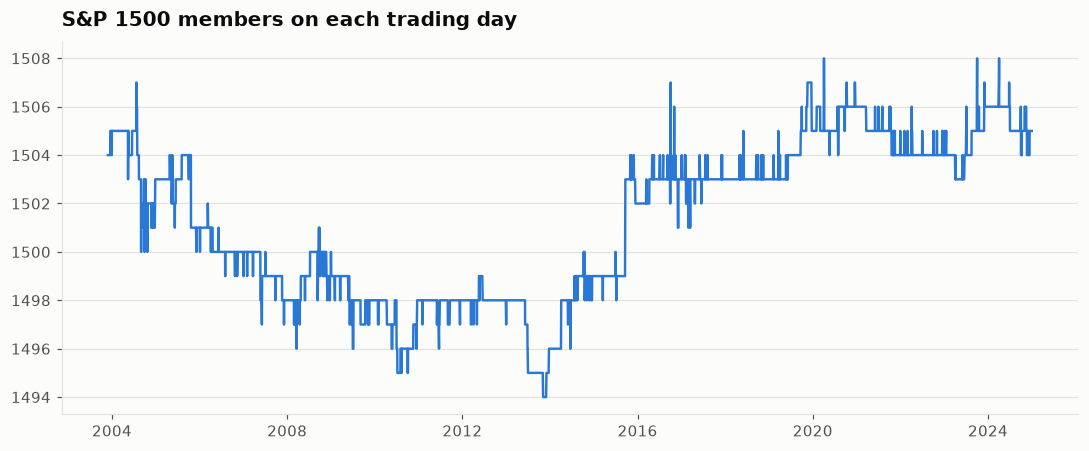

In [2]:
data = load_universe_data(cache, UNIVERSE, START, END)
days = pd.DatetimeIndex(data.returns.index)
members = data.members.reindex(index=days, columns=data.returns.columns, fill_value=False).astype(bool)
breadth = members.sum(axis=1)
fig = charts.lines({"members": breadth}, "S&P 1500 members on each trading day")
names = float(breadth.median())
need = pd.DataFrame(
    {
        f"IR {ir}": {
            f"{label} ({per} a year)": ev.required_ic(ir, names, per)
            for label, per in (("monthly", 12), ("weekly", 52), ("daily", 252))
        }
        for ir in (0.25, 0.5, 1.0)
    }
)
print(
    f"Median members: {names:,.0f}. The least IC the law allows for each information ratio "
    "(assuming every bet independent - the true need is higher):"
)
display(need.style.format("{:.4f}"))

## Step 2 - the labels

A **label** is what a model is asked to predict. Each is computed for every company and trading day from daily total
returns (dividends included); a company that stops trading keeps what it had made (a missing day counts as no change),
so a delisting is not silently dropped. Each label is stored in the artifact store, keyed by its settings and the
data snapshot, so later notebooks read it back instead of rebuilding it.

* **Forward returns** over $h$ = 1, 5 and 21 trading days: $r_{t \to t+h} = \prod_{s=t+1}^{t+h}(1 + r_s) - 1$ - the
  book's `fwd_ret_1d`, `fwd_ret_5d`, `fwd_ret_21d`.
* **Month to month**: from each month end to the next - the return a monthly rebalanced portfolio holds.
* **Triple barrier** (Lopez de Prado, 2018): imagine buying at day $t$'s close, then closing the position at the first
  of three events - the return reaches $+w\,\sigma_t\sqrt{h}$ (take profit), reaches $-w\,\sigma_t\sqrt{h}$ (stop
  loss), or $h$ days pass (the deadline). $\sigma_t$ is the share's daily volatility over the past 63 days, so a
  volatile share gets wider barriers. The label is +1, -1, or the sign of the return at the deadline. Here $h$ = 21
  and $w$ = 1: the barriers sit one typical month's move away.
* **Trend scanning** (Lopez de Prado, 2019): for each span $L$ from 5 to 21 days, fit a straight line to the log price
  over the next $L$ days, $\log P_{t+j} = a + b\,j + \varepsilon_j$, and take the $t$-statistic of the slope $b$. The
  span with the largest $|t|$ wins; its $t$-statistic is the label - its sign is the direction of the coming trend,
  its size how clear the trend is.

In [3]:
def labelled(name, config, build):
    """A label read back from the artifact store, or built and kept there."""
    return store.cached(
        "labels", name, {"universe": UNIVERSE, "start": START, "end": END} | config, build, snapshot=SNAPSHOT
    )


forward = {
    f"fwd_ret_{h}d": labelled(f"fwd_ret_{h}d", {"horizon": h}, lambda h=h: lb.forward_returns(data.returns, h))
    for h in lb.HORIZONS
}
month_ends = data.rebalances
monthly = labelled("fwd_ret_month", {"dates": "rebalances"}, lambda: lb.period_returns(data.returns, month_ends))
barrier = lb.triple_barrier(data.returns, horizon=21, width=1.0)
trend = lb.trend_scan(data.returns, spans=range(5, 22))
summary = lb.label_summary(
    forward | {"fwd_ret_month (month ends)": monthly, "trend-scan t-value": trend.t_value}, members
)
display(
    summary.style.format(
        {
            "coverage": "{:.1%}",
            "mean": "{:+.4f}",
            "sd": "{:.4f}",
            "1st percentile": "{:+.3f}",
            "99th percentile": "{:+.3f}",
        }
    )
)
print("Triple barrier (21 days, one expected move): how the trades closed")
display(lb.barrier_summary(barrier, members).to_frame("share / days").T.style.format("{:.2f}"))

,coverage,mean,sd,1st percentile,99th percentile
fwd_ret_1d,99.9%,+0.0005,0.0268,-0.071,+0.075
fwd_ret_5d,99.9%,+0.0025,0.0583,-0.158,+0.167
fwd_ret_21d,99.6%,+0.0103,0.1168,-0.308,+0.338
fwd_ret_month (month ends),99.6%,+0.0097,0.1177,-0.296,+0.332
trend-scan t-value,99.9%,+0.9596,8.1021,-16.247,+18.223


Triple barrier (21 days, one expected move): how the trades closed


,profit barrier,loss barrier,deadline,days open
share / days,0.26,0.21,0.53,16.67


## Step 3 - is a move worth trading?

Before asking whether a signal predicts a move, ask whether the move is large enough to pay for trading it. Below,
for each horizon, the typical (median) absolute return of a member over it, against the median cost of a round trip
(buying and later selling: twice the backtest's one-way cost, which is set by index segment). A ratio of 20
means a typical move covers twenty round trips; a signal then has room to be wrong often and still pay. Measured on
month ends.

In [4]:
moves = ev.move_against_cost(data.returns, data.cost_bps, month_ends, data.members, horizons=(1, 5, 21, 63))
display(moves.style.format({"median move": "{:.2%}", "round trip": "{:.2%}", "move / cost": "{:.1f}"}))

,median move,round trip,move / cost
horizon,,,
1,1.25%,0.50%,2.5
5,2.76%,0.50%,5.5
21,5.69%,0.50%,11.4
63,10.09%,0.50%,20.2


## Step 4 - the folds

A **fold** is one split of the dates into those a model learns from (training) and those it is judged on (test).
Two rules keep a fold honest:

* **Walk-forward** - the test year lies after all of its training years, as it would in real time. With data from
  2005 and ten years of training, the test years are 2015 to 2024: ten folds.
* **Purging** - a label looks forward, so the label of a training date in late December 2014 (a 21-day forward
  return) ends in January 2015, inside the test year. A model trained on it would have seen part of the test. Every
  training date whose label is not complete by the test's first day is removed.

Inside a training window, settings are tuned by **purged k-fold cross-validation**: the training dates are cut into
$k$ consecutive blocks, each block in turn is held out for validation, and training dates whose label windows touch
the block are purged. An **embargo** also drops the dates just after the block: returns are correlated from day to
day, so a date right after the block still carries information about it.

In [5]:
ends = va.label_ends(days, days, 21)
folds = va.walk_forward(days, ends, train_years=10, first_test=2015, last_test=2024)
display(va.describe(folds).style.format({c: "{:%Y-%m-%d}" for c in ("train from", "train to", "test from", "test to")}))
inner = va.purged_kfold(folds[0].train, ends, k=5, embargo=21)
print("Tuning inside fold 1's training years: five blocks, purged and embargoed (21 days)")
display(va.describe(inner).style.format({c: "{:%Y-%m-%d}" for c in ("train from", "train to", "test from", "test to")}))

,train from,train to,train dates,purged,test from,test to,test dates
fold,,,,,,,
1,2005-01-03,2014-12-01,2496,21,2015-01-02,2015-12-31,252
2,2006-01-03,2015-12-01,2496,21,2016-01-04,2016-12-30,252
3,2007-01-03,2016-11-30,2497,21,2017-01-03,2017-12-29,251
4,2008-01-02,2017-11-29,2497,21,2018-01-02,2018-12-31,251
5,2009-01-02,2018-11-28,2495,21,2019-01-02,2019-12-31,252
6,2010-01-04,2019-11-29,2495,21,2020-01-02,2020-12-31,253
7,2011-01-03,2020-12-01,2496,21,2021-01-04,2021-12-31,252
8,2012-01-03,2021-12-01,2496,21,2022-01-03,2022-12-30,251
9,2013-01-02,2022-11-30,2497,21,2023-01-03,2023-12-29,250


Tuning inside fold 1's training years: five blocks, purged and embargoed (21 days)


,train from,train to,train dates,purged,test from,test to,test dates
fold,,,,,,,
1,2007-01-30,2014-12-01,1975,21,2005-01-03,2006-12-26,500
2,2005-01-03,2014-12-01,1955,42,2006-12-27,2008-12-18,499
3,2005-01-03,2014-12-01,1955,42,2008-12-19,2010-12-13,499
4,2005-01-03,2014-12-01,1955,42,2010-12-14,2012-12-06,499
5,2005-01-03,2012-11-06,1976,21,2012-12-07,2014-12-01,499


## Step 5 - the evaluation toolkit on nine known factors

The evaluation module is tried on factors this repository already has (notebooks 3.1, 3.2 and 3.4), each as a z-score among
the members on each month end, against the next month's return (the month-to-month label). None of this is a trial:
nothing is fitted or chosen, and nothing is registered. It shows what the toolkit reports, and the
strength of the signals a model would start from.

* **Triage ledger** - each factor's mean rank IC, its Newey-West t-statistic, the two-sided p-value, and whether it
  survives **Benjamini-Hochberg** false-discovery control at 10 %: among the factors declared discoveries, at most
  about 10 % are expected to be flukes. Also the top-minus-bottom fifth's return (`spread`, per month), the share of
  the top fifth replaced each month (`turnover`) and the rank autocorrelation of the score from month to month.
  Monthly labels do not overlap, so no Newey-West lags are needed.
* **IC decay** - the same scores against forward returns of 1 to 126 days, from the month ends: how long the
  information lasts. A signal whose IC fades within days must be traded often; one that persists can be held.

,mean_ic,t_nw,p_value,discovery,spread,turnover,rank_autocorrelation
signal,,,,,,,
issuance,+0.0154,+3.53,0.000,True,+0.31%,9%,0.95
cash_flow_yield,+0.0143,+2.88,0.004,True,+0.33%,12%,0.95
quality,+0.0165,+2.46,0.014,True,+0.04%,6%,0.98
low_vol,+0.0186,+1.45,0.146,False,-0.16%,6%,0.99
accruals,-0.0042,-0.91,0.361,False,+0.25%,10%,0.95
value,+0.0054,+0.61,0.542,False,+0.32%,12%,0.97
momentum,+0.0060,+0.57,0.571,False,-0.09%,24%,0.89
earnings_surprise,+0.0020,+0.47,0.637,False,-0.03%,24%,0.77
dividend_yield,+0.0024,+0.32,0.746,False,-0.12%,4%,0.99


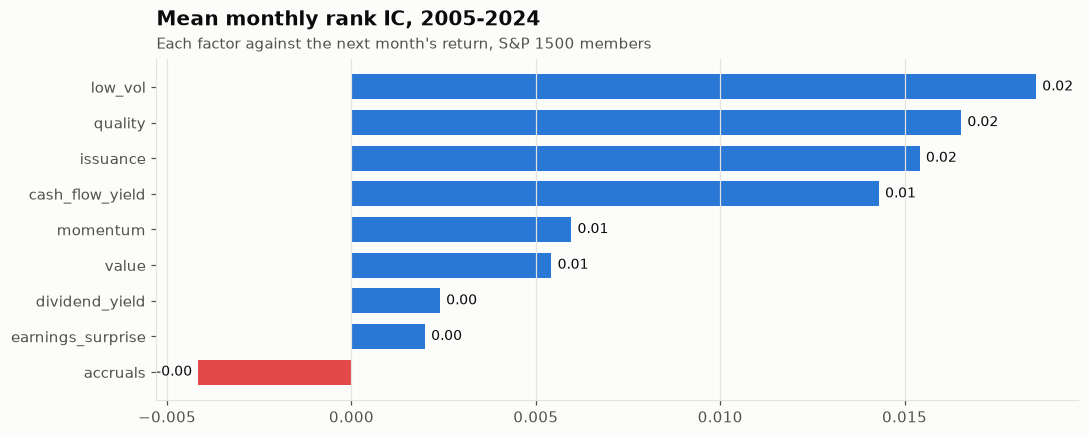

In [6]:
FACTORS = [
    "momentum",
    "low_vol",
    "value",
    "quality",
    "issuance",
    "earnings_surprise",
    "cash_flow_yield",
    "accruals",
    "dividend_yield",
]
scores = {name: factor_scores(data, name) for name in FACTORS}
ledger = ev.triage(scores, monthly, data.members, lags=0, q=0.10)
display(
    ledger.style.format(
        {
            "mean_ic": "{:+.4f}",
            "t_nw": "{:+.2f}",
            "p_value": "{:.3f}",
            "spread": "{:+.2%}",
            "turnover": "{:.0%}",
            "rank_autocorrelation": "{:.2f}",
        }
    )
)
fig = charts.ranked_bars(
    ledger["mean_ic"],
    "Mean monthly rank IC, 2005-2024",
    subtitle="Each factor against the next month's return, S&P 1500 members",
)

In [7]:
decay = pd.DataFrame(
    {
        name: ev.ic_decay(score, data.returns, data.members, horizons=(1, 5, 21, 63, 126))["mean_ic"]
        for name, score in scores.items()
    }
).T
print("Mean rank IC against the forward return over each horizon (trading days), from month ends")
display(decay.style.format("{:+.4f}").background_gradient(cmap="RdBu", vmin=-0.05, vmax=0.05, axis=None))

Mean rank IC against the forward return over each horizon (trading days), from month ends


horizon,1,5,21,63,126
momentum,+0.0250,+0.0024,+0.0060,+0.0017,+0.0015
low_vol,-0.0053,+0.0056,+0.0177,+0.0257,+0.0422
value,+0.0141,+0.0093,+0.0083,+0.0052,+0.0079
quality,+0.0027,+0.0130,+0.0183,+0.0223,+0.0308
issuance,+0.0080,+0.0215,+0.0176,+0.0254,+0.0378
earnings_surprise,+0.0142,+0.0097,+0.0020,-0.0032,-0.0042
cash_flow_yield,+0.0190,+0.0192,+0.0171,+0.0184,+0.0238
accruals,+0.0021,+0.0002,-0.0040,-0.0075,-0.0149
dividend_yield,-0.0074,-0.0041,+0.0013,+0.0046,+0.0134


## Findings

**1. Breadth is plentiful on paper, scarce in practice.** The index has a median of 1,502 members. If every monthly
bet were independent, an information ratio of 0.5 would need a rank IC of only 0.0037 (0.0008 with daily rebalancing).
The best factors below have ICs four to five times that: issuance's +0.017 would imply an information ratio of about
2.3 with monthly rebalancing. No portfolio in this repository has come close: the ones of notebook 3.3 and of those earlier studies had
information ratios between -0.65 and +0.38. Companies move together and a factor's ranking barely changes from
month to month (rank autocorrelations of 0.77 to 0.99), so the independent bets are a small fraction of the 1,502.
Later notebooks should judge a signal's IC against what its portfolio earns, not against the law's arithmetic.

**2. The labels behave as expected.** The forward returns exist for 99.6 % to 100 % of member-days; they are missing
only where the window runs past December 2024 - the labels never reach into the hold-out. Their spread grows with the
horizon roughly as $\sqrt{h}$ (a standard deviation of 2.7 % over a day, 5.9 % over five, 11.8 % over 21). With
barriers one typical month's move away, 26 % of triple-barrier trades took profit, 21 % hit the stop and 53 % ran to
the 21-day deadline, open 16.7 days on average. The excess of profit-takers over stop-losses largely reflects the
market's upward drift over 2005-2024.

**3. Short horizons barely pay for trading.** A typical (median) member moved 1.25 % in a day, 2.76 % in five days,
5.69 % in 21 and 10.09 % in 63, against a median round trip of 0.50 %. A one-day move covers 2.5 round trips: a daily
signal would have to predict a large part of each move just to break even. A 21-day move covers 11.4 and a 63-day
move 20.2. This favours monthly labels and slow signals for the plan's models, and argues for testing daily labels
only on signals whose information fades within days.

**4. Three known factors survive the triage.** Against the next month's return, 2005-2024, with Benjamini-Hochberg
control at 10 % over the nine factors:

* **Discoveries:** share issuance (IC +0.015, t +3.53), cash-flow yield (+0.014, t +2.88) and quality (+0.017,
  t +2.46).
* **Not distinguishable from zero:** low volatility (+0.019, t +1.45), accruals, momentum (+0.006, t +0.57), value
  (+0.005, t +0.61), dividend yield and the earnings surprise (+0.002, t +0.47).

Low volatility has the largest mean IC of all, but its IC swings so much from month to month (calm shares tend to hold up in falls and lag in
rallies) that its t-statistic stays low. These are monthly results; momentum's and value's weak
showing here is not a verdict on their long-run premia, only on what a month's ranking predicts over 2005-2024.

**5. Signals differ in how long their information lasts (IC decay).** Two groups emerge:

* **Fast** - momentum's IC is +0.025 against the next day's return but +0.006 at 21 days and +0.002 at 126; the
  earnings surprise's falls from +0.012 at one day to -0.007 at 126. Their information is used up within days or
  weeks, so they would have to be traded often - which point 3 says is expensive.
* **Slow** - low volatility (-0.006 at one day, +0.043 at 126), quality (+0.002 to +0.034) and issuance (+0.011 to
  +0.042) grow stronger with the horizon. Their information builds over months, so they can be held, and pay for
  their trading.

Cash-flow yield is steady at about +0.02 at every horizon.

**6. The folds are in place.** Ten walk-forward folds test 2015 to 2024, each training on the ten years before it.
Each fold has about 2,496 training days, and the 21 days whose labels would end inside the test year are purged.
Inside fold 1, five purged and embargoed blocks are ready for tuning; each loses 21 to 42 days around its validation
block.

**What this means for the plan.** P1 (features) has a measured starting point: three factors that are discoveries
on their own, a clear split between fast and slow signals, and costs that make slow signals the natural material.
P2 and P3 will judge every model against the triage of its inputs, on monthly labels first, inside these folds, with
every search registered.

## Glossary

* **Label** - the quantity a supervised model learns to predict; here always something that happens after the
  decision date.
* **Fold** - one split of dates into training and test; **walk-forward** folds keep each test after its training.
* **Purging** - removing training dates whose label windows overlap the test period.
* **Embargo** - also removing the training dates just after a validation block, because of serial correlation.
* **Cross-validation** - estimating how a setting will do on new data by fitting on part of the data and scoring on
  the rest, in turn.
* **Information coefficient (IC)** - the correlation across companies on a date between a forecast and what followed;
  *rank* IC uses Spearman's correlation of the orders.
* **Newey-West t-statistic** - a t-statistic whose standard error allows for correlation between neighbouring
  observations (as overlapping labels create).
* **Fundamental Law of Active Management** - IR is about IC times the square root of breadth (independent bets a year).
* **False-discovery rate** - among the hypotheses declared discoveries, the share expected to be false; the
  **Benjamini-Hochberg** procedure keeps it at or below a chosen level.
* **Turnover** - the share of a portfolio (here the top fifth) replaced at a rebalance; trading costs scale with it.
* **Rank autocorrelation** - the correlation of a score's ranking with its ranking a period earlier: how stable it is.
* **Artifact store** - files of computed results kept with the configuration, data snapshot and code version that
  produced them.